In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, precision_score,
    recall_score, f1_score)


In [3]:
url = (
    "https://raw.githubusercontent.com/DataTalksClub/"
    "machine-learning-zoomcamp/main/cohorts/2026/data/"
    "course_lead_scoring_2026.csv"
)

df = pd.read_csv(url)

categorical = ["lead_source", "industry", "employment_status", "location"]
numerical = ["annual_income", "number_of_courses_viewed", "interaction_count",
    "lead_score"]

features = categorical + numerical

print("Missing values:")
print(df.isna().sum())


Missing values:
lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64


In [4]:

df[categorical] = df[categorical].fillna("NA")
df[numerical] = df[numerical].fillna(0.0)

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)

df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

y_train = df_train["converted"].values
y_val = df_val["converted"].values

In [8]:
feature_auc = {}

for feature in numerical:
    score = roc_auc_score(y_train, df_train[feature])

    if score < 0.5:
        score = roc_auc_score(y_train, -df_train[feature])

    feature_auc[feature] = score

print("Q1:")
print(pd.Series(feature_auc).sort_values(ascending=False))



Q1:
lead_score                  0.788225
interaction_count           0.764920
number_of_courses_viewed    0.722989
annual_income               0.608198
dtype: float64


In [9]:
def train(df_train, y_train, C=1.0):
    train_dicts = df_train[features].to_dict(orient="records")

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(train_dicts)

    model = LogisticRegression(
        solver="liblinear",
        C=C,
        max_iter=1000,
    )
    model.fit(X_train, y_train)

    return dv, model


def predict(df, dv, model):
    dicts = df[features].to_dict(orient="records")
    X = dv.transform(dicts)

    return model.predict_proba(X)[:, 1]

dv, model = train(df_train, y_train)
y_pred = predict(df_val, dv, model)

validation_auc = roc_auc_score(y_val, y_pred)

print("Q2:", round(validation_auc, 3))

Q2: 0.732


In [10]:
rows = []

for threshold in np.linspace(0, 1, 101):
    predictions = y_pred >= threshold

    precision = precision_score(
        y_val, predictions, zero_division=0
    )
    recall = recall_score(
        y_val, predictions, zero_division=0
    )
    f1 = f1_score(
        y_val, predictions, zero_division=0
    )

    rows.append({
        "threshold": threshold,
        "precision": precision,
        "recall": recall,
        "f1": f1,
    })

df_scores = pd.DataFrame(rows)

df_scores["difference"] = (
    df_scores["precision"] - df_scores["recall"]
).abs()


In [11]:
valid_scores = df_scores[
    (df_scores["precision"] > 0) |
    (df_scores["recall"] > 0)
]

intersection = valid_scores.loc[
    valid_scores["difference"].idxmin()
]

best_f1 = df_scores.loc[df_scores["f1"].idxmax()]

print("Q3:")
print(intersection[["threshold", "precision", "recall"]])

print("Q4:")
print(best_f1[["threshold", "f1"]])

Q3:
threshold    0.630000
precision    0.732759
recall       0.725256
Name: 63, dtype: float64
Q4:
threshold    0.410000
f1           0.757616
Name: 41, dtype: float64


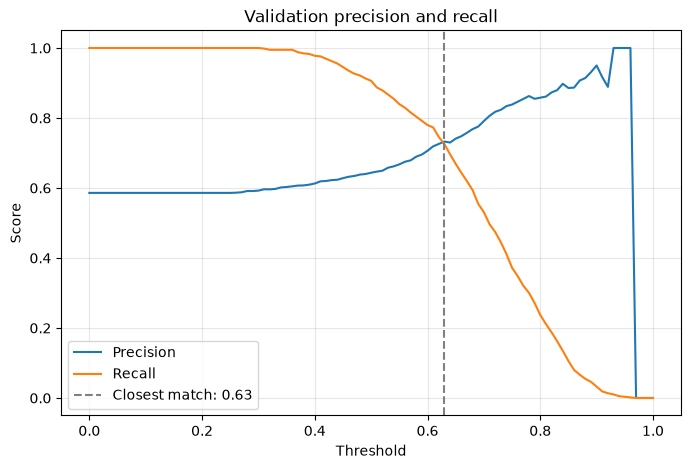

In [12]:
plt.figure(figsize=(8, 5))

plt.plot(
    df_scores["threshold"],
    df_scores["precision"],
    label="Precision",
)
plt.plot(
    df_scores["threshold"],
    df_scores["recall"],
    label="Recall",
)
plt.axvline(
    intersection["threshold"],
    color="gray",
    linestyle="--",
    label=f"Closest match: {intersection['threshold']:.2f}",
)

plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Validation precision and recall")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

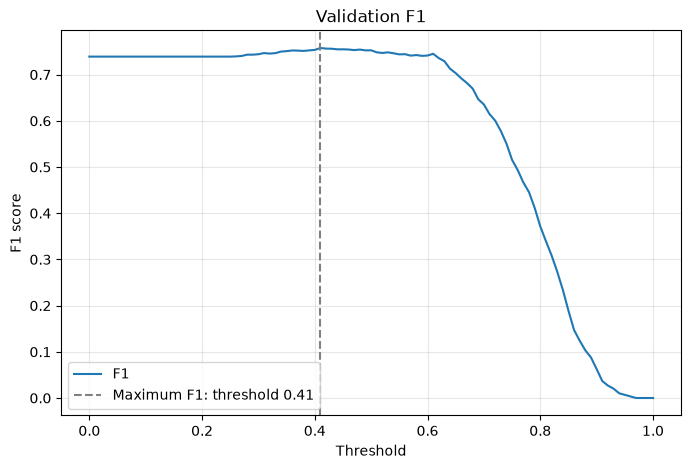

In [13]:
plt.figure(figsize=(8, 5))

plt.plot(df_scores["threshold"], df_scores["f1"], label="F1")
plt.axvline(
    best_f1["threshold"],
    color="gray",
    linestyle="--",
    label=f"Maximum F1: threshold {best_f1['threshold']:.2f}",
)

plt.xlabel("Threshold")
plt.ylabel("F1 score")
plt.title("Validation F1")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [14]:
def cross_validate(C):
    kfold = KFold(
        n_splits=5,
        shuffle=True,
        random_state=1,
    )

    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        fold_train = df_full_train.iloc[train_idx]
        fold_val = df_full_train.iloc[val_idx]

        y_fold_train = fold_train["converted"].values
        y_fold_val = fold_val["converted"].values

        # Fit a new encoder and model within each fold.
        dv, model = train(fold_train, y_fold_train, C=C)
        predictions = predict(fold_val, dv, model)

        score = roc_auc_score(y_fold_val, predictions)
        scores.append(score)

    return np.array(scores)

In [15]:
q5_scores = cross_validate(C=1.0)

print("Q5 fold scores:", q5_scores)
print("Q5 std:", round(np.std(q5_scores), 3))

Q5 fold scores: [0.7305601  0.72957261 0.73634281 0.74124547 0.72091386]
Q5 std: 0.007


In [16]:
results = []

for C in [0.000001, 0.001, 1]:
    scores = q5_scores if C == 1 else cross_validate(C)

    results.append({
        "C": C,
        "mean_auc": round(np.mean(scores), 3),
        "std_auc": round(np.std(scores), 3),
    })

results = pd.DataFrame(results)

ranked = results.sort_values(
    ["mean_auc", "std_auc", "C"],
    ascending=[False, True, True],
)

print("Q6:")
print(results.to_string(index=False))
print("Best C:", ranked.iloc[0]["C"])

Q6:
       C  mean_auc  std_auc
0.000001     0.617    0.019
0.001000     0.749    0.010
1.000000     0.732    0.007
Best C: 0.001
